# Concrete Strength MLOps: experiment review

Estimate concrete compressive strength from mixture ingredients and age, then expose the trained model through a documented batch API. The project adds split-conformal intervals, artifact identity, readiness, request validation and descriptive input monitoring to a reproducible regression experiment.

This notebook inspects the committed experiment. Run `python -m concrete_ml train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: hist_gradient_boosting
Split: {'train': 597, 'calibration': 199, 'test': 200}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test"]).T
display(comparison)

,mae,rmse,r2
mean_baseline,12.705529,15.865800,-0.007571
scaled_ridge,7.983285,9.828436,0.613348
hist_gradient_boosting,3.378990,4.830641,0.906597


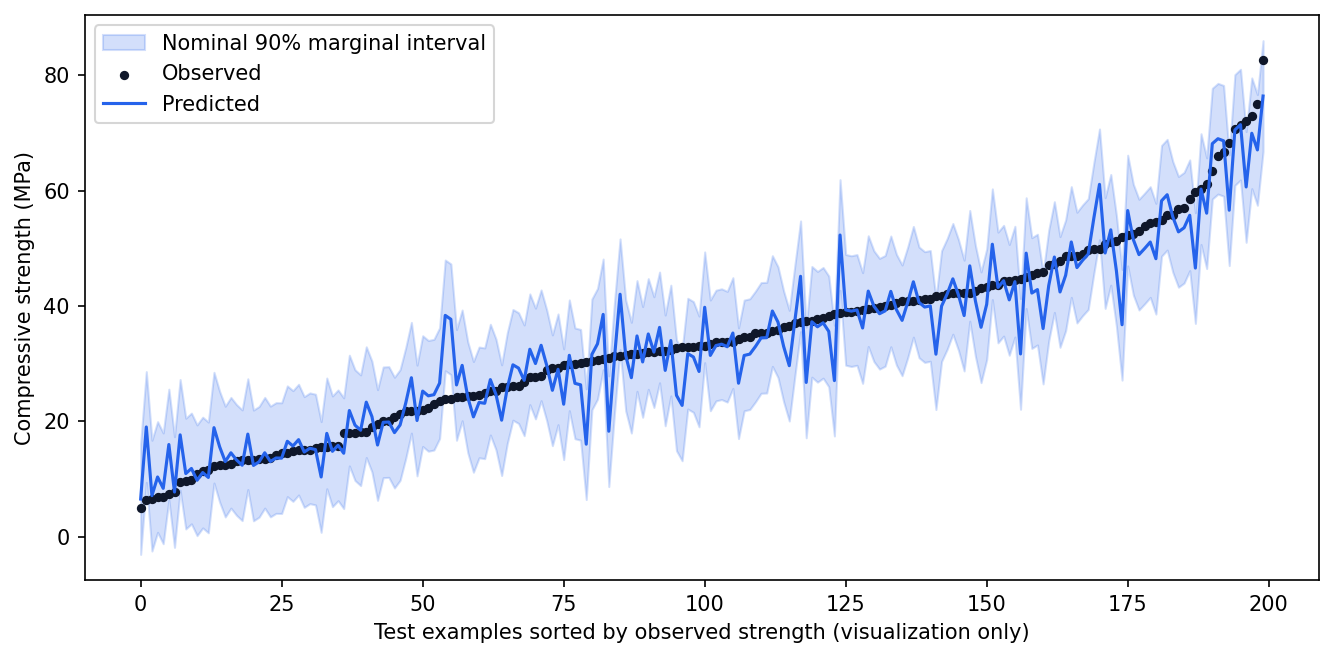

In [3]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

The boosted regressor reaches 3.379 MPa test MAE and R² 0.907 on 200 held-out feature rows. The nominal 90% interval covers 91% of the test targets and is 19.203 MPa wide. Width matters alongside coverage: a high-coverage interval can still be too broad for a decision. Similar mixture families can remain across partitions, so this is not proof of generalization to entirely new recipes or laboratories.

## Where they stop

This is a portfolio service on historical lab data and cannot approve structural designs, material specifications or safety decisions. Conformal coverage assumes exchangeability and does not survive arbitrary shift. Related recipes may cross splits. Monitoring reports training-range violations and standardized mean shifts; it does not detect accuracy degradation or establish a statistically significant distribution change. Authentication, rate limits, TLS, durable telemetry and a model registry are deployment responsibilities. The included container definition is provided; Docker was unavailable for local execution.